<a href="https://colab.research.google.com/github/ManasaRPatel/MachineLearning2_LAB/blob/main/baggingAndBoosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
cancer = load_breast_cancer()

X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target

print("Dataset shape:", X.shape)
print("\nFirst five records:")
display(X.head())

print("\nTarget classes:", cancer.target_names)

Dataset shape: (569, 30)

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target classes: ['malignant' 'benign']


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [3]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
bagging_model.fit(X_train, y_train)

# Predict
y_pred_bagging = bagging_model.predict(X_test)

print("Bagging model trained successfully!")

Bagging model trained successfully!


In [4]:
boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train the model
boosting_model.fit(X_train, y_train)

# Predict
y_pred_boosting = boosting_model.predict(X_test)

print("Boosting model trained successfully!")

Boosting model trained successfully!


In [5]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    }

results = pd.DataFrame([
    evaluate_model("Bagging", y_test, y_pred_bagging),
    evaluate_model("Boosting (AdaBoost)", y_test, y_pred_boosting)
])

print("Model Performance Comparison:")
display(results.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Bagging,0.9386,0.9452,0.9583,0.9517
1,Boosting (AdaBoost),0.9561,0.9467,0.9861,0.9660


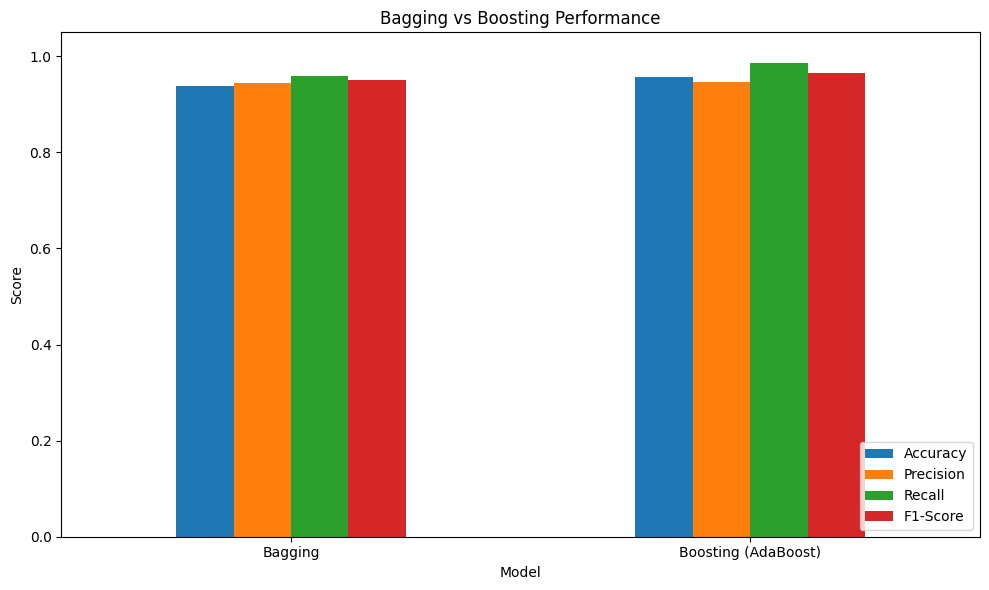

In [6]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Bagging vs Boosting Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

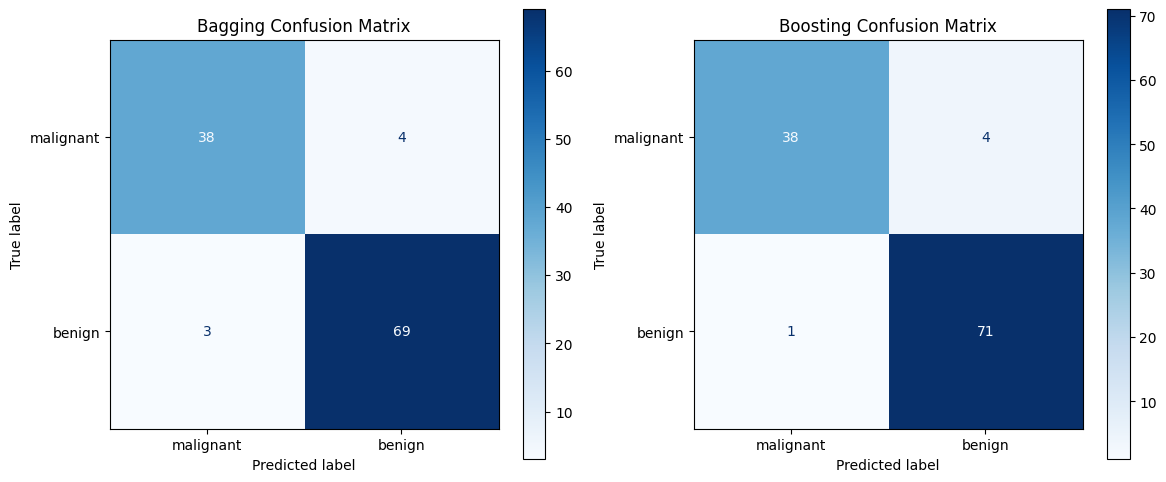

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bagging,
    display_labels=cancer.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Bagging Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_boosting,
    display_labels=cancer.target_names,
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Boosting Confusion Matrix")

plt.tight_layout()
plt.show()

In [8]:
best_model = results.loc[results["F1-Score"].idxmax()]

print("Best model based on F1-score:", best_model["Model"])
print("F1-score:", round(best_model["F1-Score"], 4))
print("Accuracy:", round(best_model["Accuracy"], 4))

Best model based on F1-score: Boosting (AdaBoost)
F1-score: 0.966
Accuracy: 0.9561
